In [2]:
import sys
sys.path.append('../src')

In [3]:
from llm import LLM
from topology import build_knn_graph, build_knn_heterogenous_graph, extend_graph_with_new_texts
from utils import get_embeddings, load_yaml, save_txt, save_tensor, load_json, save_json, append_report_row
from agents.description_generator import DescriptionGenerator
from agents.labeler import Labeler

import torch
import torch.nn.functional as F
import logging

from utils import kmeans_sample
from gnn import GNN, train_model, evaluate_model
from torch_geometric.utils import k_hop_subgraph
from collections import defaultdict
from pathlib import Path
from datasets import load_dataset

/home/jlllsarcinelli/exp/pseudo-task-agents-dev/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-06-16 13:44:00,257	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [4]:
dataset_name = 'ohsumed-single'
dataset_config = load_yaml(f'../configs/datasets/{dataset_name}.yaml')
id2label = dataset_config['id2label']

dataset = load_dataset(dataset_config['path'])
texts = list(dataset['test']['text'])
true = torch.tensor(dataset['test']['label'])
class_task_prompt = dataset_config['sentence_embed_prompt']
sentece_embed_prompt = dataset_config['sentence_embed_prompt']


In [7]:
llm_name = 'AxionML/Qwen3.5-9B-NVFP4'
sanitized_llm_name = llm_name.replace('/', '--')

In [8]:
single_descriptions = load_json(f'../cache/{dataset_name}/{sanitized_llm_name}/0/single_descriptions.json')

In [9]:
from utils import load_json, load_tensor


descriptions = load_json(f'../cache/{dataset_name}/{sanitized_llm_name}/0/descriptions.json')
examples = load_json(f'../cache/{dataset_name}/{sanitized_llm_name}/0/examples_mult.json')
sample_ids = load_tensor(f'../cache/{dataset_name}/kmeans_sample_100.pt')
sample_texts = [texts[i.item()] for i in sample_ids]
llm_labels = load_tensor(f'../cache/{dataset_name}/{sanitized_llm_name}/0/labels.pt')

examples_flat = [e for exs in examples.values() for e in exs]
descriptions_flat = [d for descs in descriptions.values() for d in descs]
descriptions_labels = torch.tensor([i for i,descs in descriptions.items() for _ in descs])
description_indices = []

offset = 0
for i,exs in examples.items():
    for j in range(len(exs)//2):
        description_indices += 2*[offset+j]
    offset += len(descriptions[i])

In [ ]:
llm = LLM(llm_name, gpu_memory_utilization=0.8, max_model_len=5096, load_model=True)
chat_kwargs = {
    'chat_template_kwargs': {
        'enable_thinking': False
    }
}
llm.set_default_chat_kwargs(chat_kwargs)

In [10]:
def get_knn_labels(embeddings, description_embeddings, description_labels, k=5, min_k=None):
    min_k = min_k or k

    sims = (embeddings @ description_embeddings.T)
    _, indices = torch.topk(sims, k=k, dim=-1)
    top_labels = description_labels[indices]
    modes,_ = top_labels.mode()
    frequencies = (top_labels == modes.unsqueeze(1)).sum(dim=1)
    knn_labels = torch.where(frequencies >= min_k, modes, torch.tensor(-1))

    return knn_labels


def show_report(knn_labels, true):
    from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
    agreement_mask = knn_labels != -1

    agreement = agreement_mask.sum()
    total = len(true)
    print(f'Agreement: {agreement}/{total} ({100*agreement/total:.2f}%)')

    print(classification_report(true[agreement_mask], knn_labels[agreement_mask], zero_division=0))
    cm = confusion_matrix(true[agreement_mask], knn_labels[agreement_mask])
    ConfusionMatrixDisplay(cm).plot(include_values=False)

    return classification_report(true[agreement_mask], knn_labels[agreement_mask], zero_division=0, output_dict=True)

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE


def plot_embedding_sets(embedding_sets, label_names=None, method="tsne", figsize=(12, 12), random_state=42):
    processed = {}
    for set_name, data in embedding_sets.items():
        print(data.keys())
        embs = data["embeddings"]
        labels = data["labels"]

        if hasattr(embs, "detach"):
            embs = embs.detach().cpu().numpy()

        if hasattr(labels, "detach"):
            labels = labels.detach().cpu().numpy()

        embs = np.asarray(embs)
        labels = np.asarray(labels)

        processed[set_name] = {
            "embeddings": embs,
            "labels": labels,
        }

    all_embeddings = np.concatenate([v["embeddings"] for v in processed.values()],axis=0)

    if method == "tsne":
        reducer = TSNE(n_components=2, random_state=random_state, init="pca", learning_rate="auto")
        X2d = reducer.fit_transform(all_embeddings)

    elif method == "pca":
        from sklearn.decomposition import PCA

        reducer = PCA(n_components=2)
        X2d = reducer.fit_transform(all_embeddings)

    else:
        raise ValueError("method must be 'tsne' or 'pca'")

    start = 0

    for set_name, data in processed.items():
        n = len(data["embeddings"])

        processed[set_name]["embeddings_2d"] = X2d[start:start+n]

        start += n

    all_labels = np.concatenate([v["labels"] for v in processed.values()])
    unique_labels = sorted(np.unique(all_labels))

    colors = (list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors) + list(plt.cm.tab20c.colors))

    if len(unique_labels) > len(colors):
        raise ValueError(
            f"Too many labels ({len(unique_labels)}). "
            f"Maximum supported is {len(colors)}."
        )

    label_to_color = { label: colors[i] for i, label in enumerate(unique_labels) }

    markers = ["o", "D", "s", "^", "v", "P", "X", "*", "<", ">"]
    alphas = np.linspace(0.35, 1.0, len(processed))
    sizes = np.linspace(40, 40, len(processed))

    plt.figure(figsize=figsize)

    for idx, (set_name, data) in enumerate(processed.items()):
        x_set = data["embeddings_2d"]
        labels = data["labels"]

        marker = markers[idx % len(markers)]
        alpha = alphas[idx]
        size = sizes[idx]

        for label in np.unique(labels):
            mask = labels == label

            name = label_names[label] if label_names is not None else str(label)

            plt.scatter(
                x_set[mask, 0],
                x_set[mask, 1],
                c=[label_to_color[label]],
                marker=marker,
                alpha=float(alpha),
                s=float(size),
                edgecolors="black",
                linewidths=0.4,
                label=f"{name} ({set_name})",
            )

    plt.title("Embedding Visualization")
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")

    handles, labels = plt.gca().get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    plt.legend(unique.values(), unique.keys(), bbox_to_anchor=(1.05, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

### Training embedding model

In [ ]:
import random
from typing import Sequence

import numpy as np
import torch
from datasets import Dataset
from sentence_transformers import SentenceTransformer
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import SentenceTransformerTrainingArguments
from sentence_transformers.trainer import SentenceTransformerTrainer


def train_text_description_aligner(
    texts: Sequence[str],
    descriptions: Sequence[str],
    description_indices: Sequence[int],
    model_name: str = "sentence-transformers/all-MiniLM-L6-v2",
    prompt=None,
    output_dir: str = "./aligned_model",
    epochs: int = 3,
    batch_size: int = 32,
    learning_rate: float = 2e-5,
    warmup_ratio: float = 0.1,
    max_length: int = 256,
    seed: int = 42,
):
    """
    Train a sentence embedding model that aligns texts with their
    corresponding descriptions.

    Parameters
    ----------
    texts : list[str]
        Input texts.

    descriptions : list[str]
        Unique descriptions/classes.

    description_indices : list[int]
        description_indices[i] gives the index of the correct
        description for texts[i].

    Example
    -------
    texts = [
        "The match ended 3-2",
        "MRI scans show tumor growth",
        "Bake at 180 degrees",
    ]

    descriptions = [
        "Sports news",
        "Medical article",
        "Cooking recipe",
    ]

    description_indices = [0, 1, 2]
    """

    assert len(texts) == len(description_indices)
    assert len(descriptions) > 0

    random.seed(seed)
    np.random.seed(seed)

    # ------------------------------------------------------------
    # Build positive pairs
    # ------------------------------------------------------------
    paired_descriptions = [
        descriptions[idx]
        for idx in description_indices
    ]

    dataset = Dataset.from_dict({
        "anchor": list(texts),
        "positive": paired_descriptions,
    })

    # ------------------------------------------------------------
    # Model
    # ------------------------------------------------------------
    model = SentenceTransformer(model_name)

    model.max_seq_length = max_length

    # ------------------------------------------------------------
    # Loss
    # ------------------------------------------------------------
    #
    # Positive:
    #   (text_i, correct_description_i)
    #
    # Negatives:
    #   all other descriptions in the batch
    #
    loss = MultipleNegativesRankingLoss(model)

    # ------------------------------------------------------------
    # Training arguments
    # ------------------------------------------------------------
    args = SentenceTransformerTrainingArguments(
        prompts=prompt,
        output_dir=output_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        learning_rate=learning_rate,
        warmup_ratio=warmup_ratio,
        fp16=torch.cuda.is_available(),
        bf16=False,
        logging_steps=10,
        save_strategy="epoch",
        save_total_limit=2,
        seed=seed,
        remove_unused_columns=False,
        report_to="none",
    )

    # ------------------------------------------------------------
    # Trainer
    # ------------------------------------------------------------
    trainer = SentenceTransformerTrainer(
        model=model,
        args=args,
        train_dataset=dataset,
        loss=loss,
    )

    # ------------------------------------------------------------
    # Train
    # ------------------------------------------------------------
    trainer.train()

    # Save final model
    model.save(output_dir)

    return model

/tmp/ipykernel_2603695/1888004752.py:10: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers.losses import MultipleNegativesRankingLoss
/tmp/ipykernel_2603695/1888004752.py:11: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import SentenceTransformerTrainingArguments
/tmp/ipykernel_2603695/1888004752.py:12: DeprecationWarning: Importing from 'sentence_transformers.trainer' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.trainer' instead.
  from sentence_transformers.trainer import SentenceTransformerTrainer


In [21]:
import random
from typing import Sequence

import numpy as np
import torch
from datasets import Dataset
from sentence_transformers import SentenceTransformer
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import SentenceTransformerTrainingArguments
from sentence_transformers.trainer import SentenceTransformerTrainer


def train_text_mult_description_aligner(
    texts: Sequence[str],
    descriptions: Sequence[str],
    description_indices: Sequence[Sequence[int]],
    model_name: str = "sentence-transformers/all-MiniLM-L6-v2",
    prompt=None,
    output_dir: str = "./aligned_model",
    epochs: int = 3,
    batch_size: int = 32,
    learning_rate: float = 2e-5,
    warmup_ratio: float = 0.1,
    max_length: int = 256,
    seed: int = 42,
):
    assert len(texts) == len(description_indices)
    assert len(descriptions) > 0

    random.seed(seed)
    np.random.seed(seed)

    anchors = []
    positives = []

    for text, desc_ids in zip(texts, description_indices):

        for desc_id in desc_ids:
            anchors.append(text)
            positives.append(descriptions[desc_id])

    dataset = Dataset.from_dict({
        "anchor": anchors,
        "positive": positives,
    })

    model = SentenceTransformer(model_name)

    model.max_seq_length = max_length

    loss = MultipleNegativesRankingLoss(model)

    args = SentenceTransformerTrainingArguments(
        prompts=prompt,
        output_dir=output_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        learning_rate=learning_rate,
        warmup_ratio=warmup_ratio,
        fp16=torch.cuda.is_available(),
        bf16=False,
        logging_steps=10,
        save_strategy='no',
        seed=seed,
        remove_unused_columns=False,
        report_to="none",
    )

    trainer = SentenceTransformerTrainer(
        model=model,
        args=args,
        train_dataset=dataset,
        loss=loss,
    )

    trainer.train()

    return model

In [ ]:
import random
from typing import Sequence

import numpy as np
import torch

from datasets import Dataset

from sentence_transformers import SentenceTransformer
from sentence_transformers.sentence_transformer.losses import MultipleNegativesRankingLoss
from sentence_transformers.sentence_transformer.training_args import (
    SentenceTransformerTrainingArguments,
)
from sentence_transformers.sentence_transformer.trainer import SentenceTransformerTrainer

from transformers import BitsAndBytesConfig

from peft import (
    LoraConfig,
    get_peft_model,
    TaskType,
)


def train_text_mult_description_aligner_lora(
    texts: Sequence[str],
    descriptions: Sequence[str],
    description_indices: Sequence[Sequence[int]],
    model_name: str = "Qwen/Qwen3-VL-Embedding-2B",
    prompt=None,
    output_dir: str = "./aligned_model",
    epochs: int = 3,
    batch_size: int = 2,
    gradient_accumulation_steps: int = 16,
    learning_rate: float = 2e-5,
    warmup_ratio: float = 0.1,
    max_length: int = 512,
    seed: int = 42,
):
    assert len(texts) == len(description_indices)
    assert len(descriptions) > 0

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    anchors = []
    positives = []

    for text, desc_ids in zip(texts, description_indices):
        for desc_id in desc_ids:
            anchors.append(text)
            positives.append(descriptions[desc_id])

    dataset = Dataset.from_dict({
        "anchor": anchors,
        "positive": positives,
    })

    model = SentenceTransformer(
        model_name,
        model_kwargs={
            "torch_dtype": torch.float16,
            "device_map": "auto",
        },
    )

    model.max_seq_length = max_length

    transformer_model = model[0].auto_model

    transformer_model.gradient_checkpointing_enable()

    # important for checkpointing
    transformer_model.enable_input_require_grads()

    lora_config = LoraConfig(
        r=16,
        lora_alpha=32,
        target_modules=[
            "q_proj",
            "k_proj",
            "v_proj",
            "o_proj",
        ],
        lora_dropout=0.05,
        bias="none",
        task_type=TaskType.FEATURE_EXTRACTION,
    )

    transformer_model = get_peft_model(
        transformer_model,
        lora_config,
    )

    model[0].auto_model = transformer_model

    transformer_model.print_trainable_parameters()

    loss = MultipleNegativesRankingLoss(model)

    args = SentenceTransformerTrainingArguments(
        prompts=prompt,
        output_dir=output_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        gradient_accumulation_steps=gradient_accumulation_steps,
        learning_rate=learning_rate,
        warmup_ratio=warmup_ratio,
        fp16=True,
        bf16=False,
        logging_steps=10,
        save_strategy="epoch",
        save_total_limit=2,
        seed=seed,
        remove_unused_columns=False,
        report_to="none",
        gradient_checkpointing=True,
        dataloader_pin_memory=False,
    )

    trainer = SentenceTransformerTrainer(
        model=model,
        args=args,
        train_dataset=dataset,
        loss=loss,
    )

    trainer.train()

    return model

In [13]:
import random
from typing import Sequence

import numpy as np
import torch

from datasets import Dataset

from sentence_transformers import SentenceTransformer
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import (
    SentenceTransformerTrainingArguments,
)
from sentence_transformers.trainer import SentenceTransformerTrainer


def train_text_mult_description_aligner_frozen(
    texts: Sequence[str],
    descriptions: Sequence[str],
    description_indices: Sequence[Sequence[int]],
    model_name: str = "Qwen/Qwen3-VL-Embedding-2B",
    prompt=None,
    output_dir: str = "./aligned_model",
    epochs: int = 3,
    batch_size: int = 2,
    gradient_accumulation_steps: int = 16,
    learning_rate: float = 2e-5,
    warmup_ratio: float = 0.1,
    max_length: int = 128,
    seed: int = 42,
):
    assert len(texts) == len(description_indices)
    assert len(descriptions) > 0

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # ------------------------------------------------------------
    # Build positive pairs
    # ------------------------------------------------------------

    anchors = []
    positives = []

    for text, desc_ids in zip(texts, description_indices):
        for desc_id in desc_ids:
            anchors.append(text)
            positives.append(descriptions[desc_id])

    dataset = Dataset.from_dict({
        "anchor": anchors,
        "positive": positives,
    })

    # ------------------------------------------------------------
    # Load model
    # ------------------------------------------------------------

    model = SentenceTransformer(
        model_name,
        model_kwargs={
            "torch_dtype": torch.float16,
            "device_map": "auto",
        },
    )

    model.max_seq_length = max_length

    # ------------------------------------------------------------
    # Access underlying HF model
    # ------------------------------------------------------------

    transformer_model = model[0].auto_model

    # ------------------------------------------------------------
    # Freeze multimodal / vision weights
    # ------------------------------------------------------------

    multimodal_keywords = [
        "visual",
        "vision",
        "image",
        "img",
        "vit",
        "vision_tower",
        "multi_modal",
    ]

    frozen_params = 0
    trainable_params = 0

    for name, param in transformer_model.named_parameters():

        if any(k in name.lower() for k in multimodal_keywords):
            param.requires_grad = False
            frozen_params += param.numel()
        else:
            param.requires_grad = True
            trainable_params += param.numel()

    print(f"Frozen params: {frozen_params:,}")
    print(f"Trainable params: {trainable_params:,}")

    # ------------------------------------------------------------
    # Gradient checkpointing
    # ------------------------------------------------------------

    transformer_model.gradient_checkpointing_enable()
    transformer_model.enable_input_require_grads()

    # ------------------------------------------------------------
    # Loss
    # ------------------------------------------------------------

    loss = MultipleNegativesRankingLoss(model)

    # ------------------------------------------------------------
    # Training arguments
    # ------------------------------------------------------------

    args = SentenceTransformerTrainingArguments(
        prompts=prompt,
        output_dir=output_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        gradient_accumulation_steps=gradient_accumulation_steps,
        learning_rate=learning_rate,
        warmup_ratio=warmup_ratio,
        logging_steps=10,
        save_strategy="epoch",
        save_total_limit=2,
        seed=seed,
        remove_unused_columns=False,
        report_to="none",
        gradient_checkpointing=True,
        dataloader_pin_memory=False,
    )

    # ------------------------------------------------------------
    # Trainer
    # ------------------------------------------------------------

    trainer = SentenceTransformerTrainer(
        model=model,
        args=args,
        train_dataset=dataset,
        loss=loss,
    )

    # ------------------------------------------------------------
    # Train
    # ------------------------------------------------------------

    trainer.train()

    # ------------------------------------------------------------
    # Save
    # ------------------------------------------------------------

    model.save(output_dir)

    return model

In [5]:
from utils import load_json, load_tensor


descriptions = load_json(f'../cache/{dataset_name}/AxionML--Qwen3.5-9B-NVFP4/0/descriptions.json')
examples = load_json(f'../cache/{dataset_name}/AxionML--Qwen3.5-9B-NVFP4/0/examples_mult.json')
sample_ids = load_tensor(f'../cache/{dataset_name}/kmeans_sample_100.pt')
sample_texts = [texts[i.item()] for i in sample_ids]
llm_labels = load_tensor(f'../cache/{dataset_name}/AxionML--Qwen3.5-9B-NVFP4/0/labels.pt')

examples_flat = [e for exs in examples.values() for e in exs]
descriptions_flat = [d for descs in descriptions.values() for d in descs]
descriptions_labels = torch.tensor([i for i,descs in descriptions.items() for _ in descs])
description_indices = []

offset = 0
for i,exs in examples.items():
    for j in range(len(exs)//2):
        description_indices += 2*[offset+j]
    offset += len(descriptions[i])

In [ ]:
from agents.description_matcher import DescriptionMatcher


desc_match_agent = DescriptionMatcher(class_task_prompt, id2label, llm)
matches = desc_match_agent.match_descriptions(sample_texts, llm_labels[sample_ids].tolist(), descriptions)
save_json(matches, 'matches.json')

In [ ]:
llm.unload_model()

In [6]:
matches = load_json('matches.json')

In [ ]:
global_matches = []
for i,match in zip(true[sample_ids], matches):
    offset = sum(len(descriptions[j]) for j in range(i.item()))
    gms = []
    for m in match:
        if m < len(descriptions[i.item()]):
            gms += [offset+m]
    global_matches.append(gms)

In [ ]:
from sklearn.metrics import classification_report

prompt = f'task: sentence similariy | query: {class_task_prompt} - '
model = SentenceTransformer("Qwen/Qwen3-Embedding-0.6B")
emb_texts = model.encode(texts, prompt=prompt, normalize_embeddings=True, convert_to_tensor=True).cpu()
emb_descs = model.encode(descriptions_flat, prompt=prompt, normalize_embeddings=True, convert_to_tensor=True).cpu()
description_labels = torch.tensor([i for i,descs in enumerate(descriptions.values()) for _ in descs])

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 20463.88it/s]


Agreement: 514/4043 (12.71%)
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         3
           1       0.00      0.00      0.00         2
           2       0.95      1.00      0.97        19
           3       0.81      0.90      0.85       198
           4       0.00      0.00      0.00         3
           5       1.00      0.11      0.20         9
           6       0.67      1.00      0.80         2
           7       0.78      0.58      0.67        12
           8       0.17      1.00      0.29         1
           9       0.00      0.00      0.00        11
          10       0.75      1.00      0.86        60
          11       1.00      0.05      0.09        22
          12       0.00      0.00      0.00        11
          13       1.00      0.14      0.25         7
          14       0.00      0.00      0.00         3
          15       0.08      0.11      0.09         9
          16       0.00      0.00      0.00        1

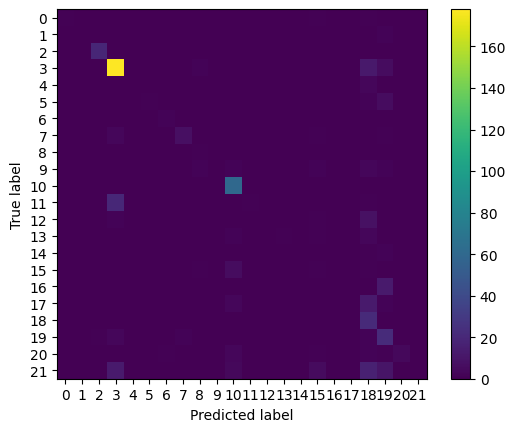

In [15]:
knn_labels = get_knn_labels(emb_texts, emb_descs, description_labels, min_k=5)

_ = show_report(knn_labels, true)

In [22]:
model = train_text_mult_description_aligner(
    texts=sample_texts,
    descriptions=descriptions_flat,
    description_indices=global_matches,
    model_name='Qwen/Qwen3-Embedding-0.6B',
    output_dir="./qwen_aligner",
    prompt=prompt,
    epochs=10,
    batch_size=8,
    learning_rate=2e-5,
    max_length=512,
)

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 12927.75it/s]
The `warmup_ratio` argument is deprecated in Transformers v5+, and will also be removed from Sentence Transformers once support for Transformers v4 is dropped. Since you're using Transformers v5+, please use `warmup_steps` (as a float) to specify the warmup ratio instead.


NotImplementedError: "_amp_foreach_non_finite_check_and_unscale_cuda" not implemented for 'BFloat16'

In [30]:
emb_descs = model.encode(descriptions_flat, prompt=prompt, normalize_embeddings=True, convert_to_tensor=True).cpu()
emb_texts = model.encode(texts, prompt=prompt, normalize_embeddings=True, convert_to_tensor=True).cpu()

Agreement: 2028/4043 (50.16%)
              precision    recall  f1-score   support

           0       0.78      0.37      0.50        19
           1       0.00      0.00      0.00         1
           2       1.00      0.89      0.94        19
           3       0.85      0.75      0.80       247
           4       0.45      0.69      0.55        59
           5       0.79      0.72      0.75        64
           6       0.55      0.86      0.67        21
           7       0.69      0.93      0.79        95
           8       0.47      0.94      0.62        16
           9       0.63      0.80      0.71       217
          10       0.69      0.94      0.80        72
          11       0.85      0.72      0.78       116
          12       0.51      0.88      0.65        57
          13       0.82      0.97      0.89       504
          14       0.00      0.00      0.00        12
          15       0.50      0.03      0.06        29
          16       0.81      0.73      0.77        

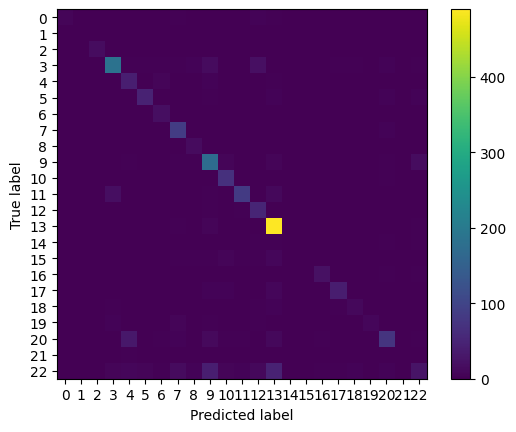

In [32]:
knn_labels = get_knn_labels(emb_texts, emb_descs, descriptions_labels, min_k=5)

_ = show_report(knn_labels, true)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16832.78it/s]


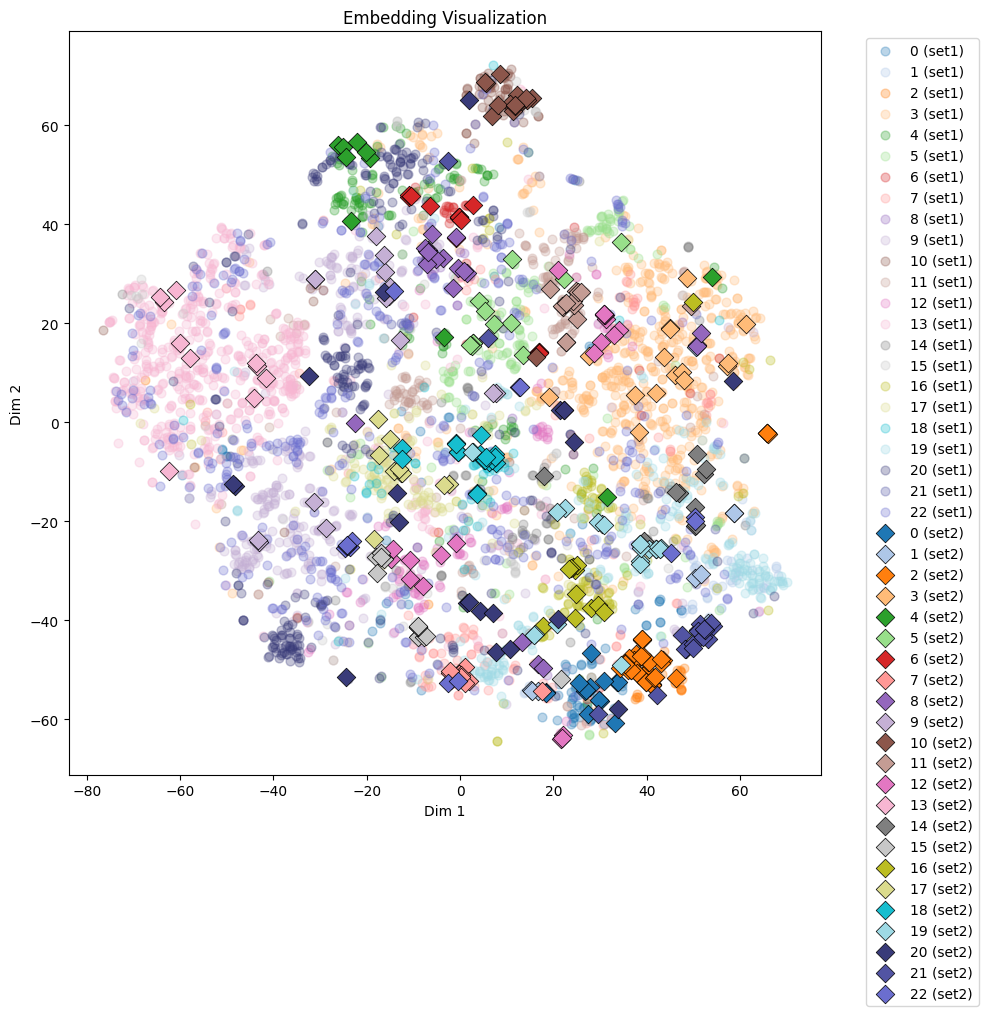

In [ ]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

emb_texts = model.encode(texts, prompt=class_task_prompt, normalize_embeddings=True, convert_to_tensor=True).cpu()
emb_examples = model.encode(examples_flat, prompt=class_task_prompt, normalize_embeddings=True, convert_to_tensor=True).cpu()
emb_descs = model.encode(descriptions_flat, prompt=class_task_prompt, normalize_embeddings=True, convert_to_tensor=True).cpu()

plot_embedding_sets(emb_texts, true, emb_examples, examples_labels)

### Hetero node generator

In [38]:
from importlib import reload

import agents
reload(agents)

<module 'agents' (namespace) from ['/exp/jlllsarcinelli/pseudo-task-agents-dev/notebooks/../src/agents']>

In [39]:
from agents.hetero_node_generator import HeteroNodeGenerator


hetero_node_generator = HeteroNodeGenerator(class_task_prompt, id2label, llm)

In [40]:
hetero_nodes = hetero_node_generator.get_nodes(single_descriptions, texts, n=5)

INFO 05-29 14:39:21 [utils.py:233] non-default args: {'trust_remote_code': True, 'max_model_len': 6000, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'model': 'AxionML/Qwen3.5-9B-NVFP4'}
INFO 05-29 14:39:21 [model.py:549] Resolved architecture: Qwen3_5ForConditionalGeneration
INFO 05-29 14:39:21 [model.py:1678] Using max model len 6000
INFO 05-29 14:39:21 [config.py:281] Setting attention block size to 528 tokens to ensure that attention page size is >= mamba page size.
INFO 05-29 14:39:21 [config.py:312] Padding mamba page size by 0.76% to ensure that mamba page size and attention page size are exactly equal.
WARNING 05-29 14:39:21 [modelopt.py:998] Detected ModelOpt NVFP4 checkpoint. Please note that the format is experimental and could change in future.
(EngineCore pid=2640479) INFO 05-29 14:39:36 [core.py:105] Initializing a V1 LLM engine (v0.19.1) with config: model='AxionML/Qwen3.5-9B-NVFP4', speculative_config=None, tokenizer='AxionML/Qwen3.5-9B-NVFP4', skip_tokenize

(EngineCore pid=2640479) [transformers] `Qwen2VLImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Qwen2VLImageProcessor` instead.


(EngineCore pid=2640479) INFO 05-29 14:39:38 [parallel_state.py:1400] world_size=1 rank=0 local_rank=0 distributed_init_method=tcp://10.10.10.23:34277 backend=nccl
(EngineCore pid=2640479) INFO 05-29 14:39:38 [parallel_state.py:1716] rank 0 in world size 1 is assigned as DP rank 0, PP rank 0, PCP rank 0, TP rank 0, EP rank N/A, EPLB rank N/A


(EngineCore pid=2640479) [transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


(EngineCore pid=2640479) INFO 05-29 14:39:48 [gpu_model_runner.py:4735] Starting to load model AxionML/Qwen3.5-9B-NVFP4...
(EngineCore pid=2640479) INFO 05-29 14:39:48 [cuda.py:390] Using backend AttentionBackendEnum.FLASH_ATTN for vit attention
(EngineCore pid=2640479) INFO 05-29 14:39:48 [mm_encoder_attention.py:230] Using AttentionBackendEnum.FLASH_ATTN for MMEncoderAttention.
(EngineCore pid=2640479) INFO 05-29 14:39:48 [nvfp4_utils.py:85] Using NvFp4LinearBackend.MARLIN for NVFP4 GEMM
(EngineCore pid=2640479) INFO 05-29 14:39:48 [gdn_linear_attn.py:147] Using Triton/FLA GDN prefill kernel
(EngineCore pid=2640479) INFO 05-29 14:39:49 [cuda.py:334] Using FLASH_ATTN attention backend out of potential backends: ['FLASH_ATTN', 'FLASHINFER', 'TRITON_ATTN', 'FLEX_ATTENTION'].
(EngineCore pid=2640479) INFO 05-29 14:39:49 [flash_attn.py:596] Using FlashAttention version 2


...

(EngineCore pid=2640479) /home/jlllsarcinelli/exp/pseudo-task-agents-dev/.venv/lib/python3.12/site-packages/vllm/model_executor/layers/fla/ops/utils.py:113: UserWarning: Input tensor shape suggests potential format mismatch: seq_len (16) < num_heads (32). This may indicate the inputs were passed in head-first format [B, H, T, ...] when head_first=False was specified. Please verify your input tensor format matches the expected shape [B, T, H, ...].
(EngineCore pid=2640479)   return fn(*contiguous_args, **contiguous_kwargs)


(EngineCore pid=2640479) INFO 05-29 14:40:02 [monitor.py:76] Initial profiling/warmup run took 0.91 s
(EngineCore pid=2640479) INFO 05-29 14:40:02 [kv_cache_utils.py:829] Overriding num_gpu_blocks=0 with num_gpu_blocks_override=512
(EngineCore pid=2640479) INFO 05-29 14:40:02 [gpu_model_runner.py:5876] Profiling CUDA graph memory: PIECEWISE=51 (largest=512), FULL=35 (largest=256)
(EngineCore pid=2640479) INFO 05-29 14:40:03 [gpu_model_runner.py:5955] Estimated CUDA graph memory: 0.71 GiB total
(EngineCore pid=2640479) INFO 05-29 14:40:03 [gpu_worker.py:436] Available KV cache memory: 8.38 GiB
(EngineCore pid=2640479) INFO 05-29 14:40:03 [gpu_worker.py:470] In v0.19, CUDA graph memory profiling will be enabled by default (VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=1), which more accurately accounts for CUDA graph memory during KV cache allocation. To try it now, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=1 and increase --gpu-memory-utilization from 0.8000 to 0.8304 to maintain the same 

Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|██████████| 51/51 [00:01<00:00, 27.48it/s]
Capturing CUDA graphs (decode, FULL): 100%|██████████| 35/35 [00:01<00:00, 31.98it/s]


(EngineCore pid=2640479) INFO 05-29 14:40:07 [gpu_model_runner.py:6046] Graph capturing finished in 3 secs, took 0.60 GiB
(EngineCore pid=2640479) INFO 05-29 14:40:07 [gpu_worker.py:597] CUDA graph pool memory: 0.6 GiB (actual), 0.71 GiB (estimated), difference: 0.12 GiB (19.6%).
(EngineCore pid=2640479) INFO 05-29 14:40:07 [core.py:283] init engine (profile, create kv cache, warmup model) took 11.76 seconds
(EngineCore pid=2640479) INFO 05-29 14:40:07 [vllm.py:790] Asynchronous scheduling is enabled.
(EngineCore pid=2640479) INFO 05-29 14:40:07 [compilation.py:292] Enabled custom fusions: act_quant


Processed prompts: 100%|██████████| 115/115 [00:22<00:00,  5.19it/s, est. speed input: 9912.55 toks/s, output: 32.85 toks/s]


In [41]:
hetero_nodes

defaultdict(list,
            {0: ['pathogen etiology',
              'pathogen virulence mechanisms',
              'pathogen-induced infection',
              'infectious etiology identification',
              'pathogen identification'],
             1: ['viral pathogen etiology',
              'viral pathogen induced immune response',
              'viral pathogen infection',
              'viral pathogen etiology',
              'viral pathogen etiology'],
             2: ['Parasitic Organism Infection',
              'parasitic organism host-tissue invasion',
              'parasitic host-tissue invasion',
              'pathogen-host interaction',
              'parasitic host-tissue invasion'],
             3: ['tumor growth and metastasis',
              'tumor antigen functional domains',
              'tumor markers',
              'tumor recurrence',
              'tumor growth and treatment'],
             4: ['musculoskeletal structural integrity and mobility',
          

In [44]:
llm.unload_model()

(EngineCore pid=2640479) INFO 05-29 14:45:34 [core.py:1210] Shutdown initiated (timeout=0)
(EngineCore pid=2640479) INFO 05-29 14:45:34 [core.py:1233] Shutdown complete


[rank0]:[W529 14:45:34.655123263 ProcessGroupNCCL.cpp:1553] Warning: WARNING: destroy_process_group() was not called before program exit, which can leak resources. For more info, please see https://pytorch.org/docs/stable/distributed.html#shutdown (function operator())


In [33]:
dict(hetero_nodes)
hetero_nodes_flat = [n for nodes in hetero_nodes.values() for n in nodes]
hetero_nodes_labels = torch.tensor([i for i,nodes in hetero_nodes.items() for _ in nodes])

hetero_node_embeddings = get_embeddings(hetero_nodes_flat, class_task_prompt)

Loading weights: 100%|██████████| 625/625 [00:00<00:00, 17412.65it/s]


In [18]:
emb_texts = get_embeddings(texts, class_task_prompt)

Loading weights: 100%|██████████| 625/625 [00:00<00:00, 14651.79it/s]


Agreement: 4043/4043 (100.00%)
              precision    recall  f1-score   support

           0       0.51      0.33      0.40       102
           1       0.39      0.32      0.35        50
           2       0.72      0.79      0.75        29
           3       0.70      0.50      0.58       600
           4       0.33      0.59      0.42       140
           5       0.48      0.74      0.58       178
           6       0.37      0.85      0.51        34
           7       0.24      0.14      0.18       129
           8       0.10      0.14      0.12        28
           9       0.49      0.63      0.55       342
          10       0.59      0.89      0.71        76
          11       0.74      0.21      0.33       187
          12       0.47      0.64      0.55       103
          13       0.51      0.90      0.65       590
          14       0.21      0.46      0.29        79
          15       0.21      0.43      0.29        70
          16       0.62      0.60      0.61       

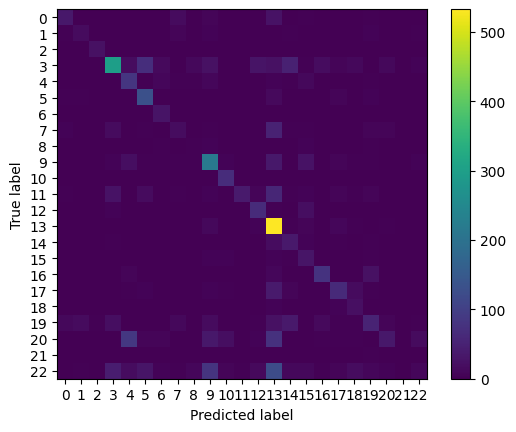

In [37]:
knn_labels = get_knn_labels(emb_texts, hetero_node_embeddings, hetero_nodes_labels, k=5, min_k=1)
_ = show_report(knn_labels, true)

### Check unagreeing nodes

In [11]:
emb_descs = get_embeddings(descriptions_flat, sentece_embed_prompt)
emb_texts = get_embeddings(texts, sentece_embed_prompt)

Loading weights: 100%|██████████| 625/625 [00:16<00:00, 38.55it/s] 
Default prompt name is set to 'default'. This prompt will be applied to all inference calls, except if a `prompt` or `prompt_name` parameter is provided.
Loading weights: 100%|██████████| 625/625 [00:00<00:00, 12821.66it/s]


In [12]:
single_desc_labels = torch.arange(len(id2label))

In [13]:
sims = (emb_texts @ emb_descs.T)
_, indices = torch.topk(sims, k=5, dim=-1)
top_labels = descriptions_labels[indices]
modes,_ = top_labels.mode()
frequencies = (top_labels == modes.unsqueeze(1)).sum(dim=1)


In [36]:
knn_labels = get_knn_labels(emb_texts, emb_descs, descriptions_labels)

In [40]:
(knn_labels != -1).sum()

tensor(1349)

In [50]:
llm_labels = torch.load('../cache/ohsumed-single/AxionML--Qwen3.5-9B-NVFP4/0/labels.pt')

dict_keys(['embeddings', 'labels'])
dict_keys(['embeddings', 'labels'])


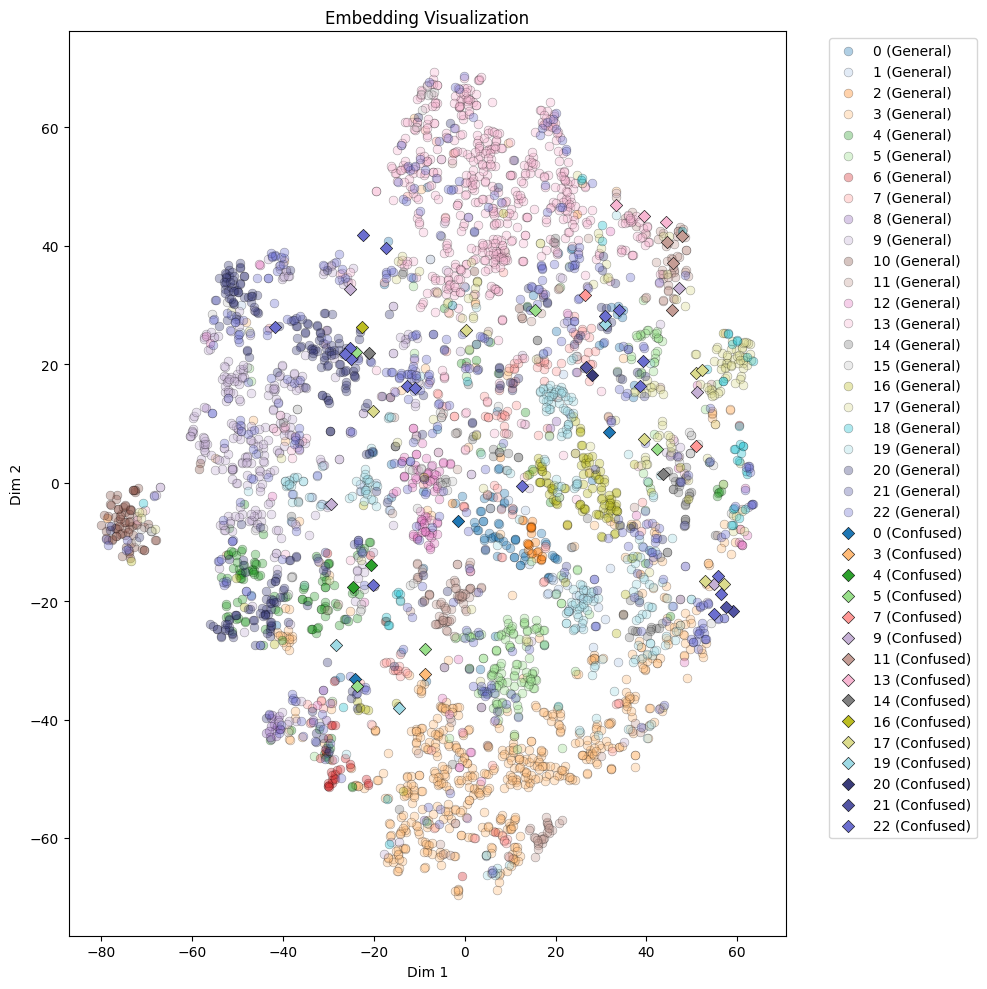

In [51]:
confused_indices = (frequencies == 1).nonzero().flatten()
confused_embeddings = emb_texts[confused_indices]
confused_labels = true[confused_indices]
plot_embedding_sets({
    'General': {
        'embeddings': emb_texts,
        'labels': true
    },
    'Confused': {
        'embeddings': confused_embeddings, 
        # 'labels': knn_labels[knn_labels != -1]
        # 'labels': confused_labels,
        'labels': llm_labels[confused_indices]
    }
}, figsize=(10, 10))

In [56]:
knn_labels[(knn_labels != -1) & (knn_labels != llm_labels)].shape

torch.Size([186])

Agreement: 1349/4043 (33.37%)
              precision    recall  f1-score   support

           0       1.00      0.67      0.80        12
           1       0.67      0.50      0.57         4
           2       0.95      0.90      0.93        21
           3       0.84      0.83      0.84       228
           4       0.37      0.78      0.50        50
           5       0.86      0.94      0.90        34
           6       0.55      0.94      0.69        18
           7       0.53      0.40      0.45        25
           8       0.50      1.00      0.67        16
           9       0.73      0.86      0.79       129
          10       0.74      1.00      0.85        64
          11       0.89      0.82      0.85        71
          12       0.72      0.89      0.80        44
          13       0.90      0.96      0.93       305
          14       0.00      0.00      0.00         1
          15       0.38      0.38      0.38        16
          16       0.95      0.69      0.80        

{'0': {'precision': 1.0,
  'recall': 0.6666666666666666,
  'f1-score': 0.8,
  'support': 12.0},
 '1': {'precision': 0.6666666666666666,
  'recall': 0.5,
  'f1-score': 0.5714285714285714,
  'support': 4.0},
 '2': {'precision': 0.95,
  'recall': 0.9047619047619048,
  'f1-score': 0.926829268292683,
  'support': 21.0},
 '3': {'precision': 0.84375,
  'recall': 0.8289473684210527,
  'f1-score': 0.8362831858407079,
  'support': 228.0},
 '4': {'precision': 0.36792452830188677,
  'recall': 0.78,
  'f1-score': 0.5,
  'support': 50.0},
 '5': {'precision': 0.8648648648648649,
  'recall': 0.9411764705882353,
  'f1-score': 0.9014084507042254,
  'support': 34.0},
 '6': {'precision': 0.5483870967741935,
  'recall': 0.9444444444444444,
  'f1-score': 0.6938775510204082,
  'support': 18.0},
 '7': {'precision': 0.5263157894736842,
  'recall': 0.4,
  'f1-score': 0.45454545454545453,
  'support': 25.0},
 '8': {'precision': 0.5,
  'recall': 1.0,
  'f1-score': 0.6666666666666666,
  'support': 16.0},
 '9': {'p

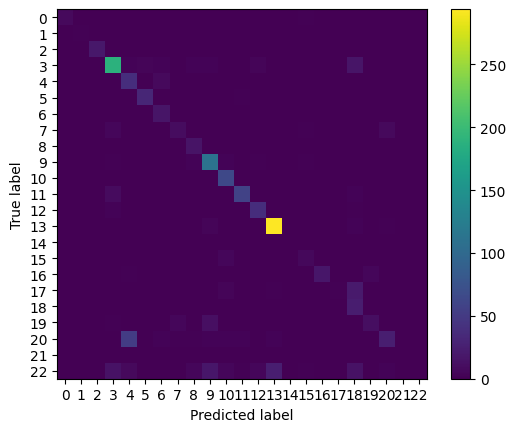

In [31]:
knn_labels = get_knn_labels(emb_texts, emb_descs, descriptions_labels)
show_report(knn_labels, true)